# Modeling

### Import Libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import plotly.express as px
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import umap

/mnt/c/Users/frank/cs231-project-fishing/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Constants

In [3]:
PROCESSED_TRSHMNT_DIR_FROM_CWD = "../data/processed/transshipment"
PROCESSED_LOITERING_FILENAME = "processed-loitering-events.csv"

RANDOM_SEED = 21

K_MEANS_N_INIT = 10

### Set Seed for Reproducible Random Number Generation

In [4]:
np.random.seed(RANDOM_SEED)

## Modeling Loitering Events

### Load Processed Dataset

In [5]:
loitering_df = pd.read_csv(
    os.path.join(
        os.getcwd(),
        PROCESSED_TRSHMNT_DIR_FROM_CWD,
        PROCESSED_LOITERING_FILENAME
    )
)
loitering_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 46569 entries, 0 to 46568
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   transshipment_mmsi    46569 non-null  int64  
 1   starting_latitude     46569 non-null  float64
 2   starting_longitude    46569 non-null  float64
 3   ending_latitude       46569 non-null  float64
 4   ending_longitude      46569 non-null  float64
 5   starting_timestamp    46569 non-null  str    
 6   ending_timestamp      46569 non-null  str    
 7   median_speed_knots    46569 non-null  float64
 8   total_event_duration  46569 non-null  float64
 9   diff_lat              46569 non-null  float64
 10  diff_long             46569 non-null  float64
 11  movement_mag          46569 non-null  float64
 12  local_hour            46569 non-null  float64
 13  is_night_corrected    46569 non-null  int64  
 14  nearest_mpa_name      46569 non-null  str    
 15  nearest_mpa_lat       46569 no

### 1. Principal Component Analysis (PCA)

#### 1. Select and Scale Features

In [6]:
loitering_PCA_features = ['total_event_duration', 'median_speed_knots', 'nearest_mpa_dist', 'movement_mag', 'local_hour', 'is_night_corrected', 'starting_latitude', 'starting_longitude', 'ending_latitude', 'ending_longitude']
loitering_PCA_X = loitering_df[loitering_PCA_features]

loitering_PCA_scaler = StandardScaler()
loitering_PCA_X_scaled = loitering_PCA_scaler.fit_transform(loitering_PCA_X)

#### 2. Analyze Explained Variance

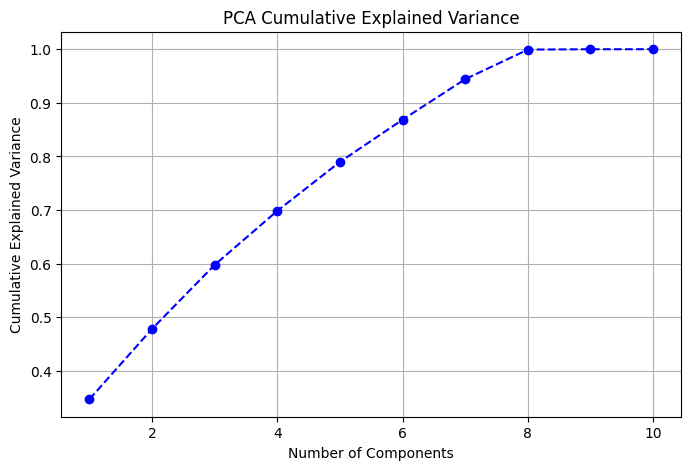

In [7]:
loitering_PCA_full = PCA()
loitering_PCA_full.fit(loitering_PCA_X_scaled)
cum_sum = np.cumsum(loitering_PCA_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_sum) + 1), cum_sum, marker='o', linestyle='--', color='b')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid()
plt.show()

The cumulative explained variance levels off at 8 components with 100% explained variance. 95% of the variance is also explained with 7 components.

#### 3. Reduce Features to 7 Principal Components

In [8]:
loitering_PCA = PCA(n_components=7)
loitering_X_PCA = loitering_PCA.fit_transform(loitering_PCA_X_scaled)

### 2. K-Means Clustering

#### 1. Test Clusters with Varying Ks

In [9]:
wcss = []
silhouette_avg = []
k_range = range(2, 10)

for k in k_range:
    k_means = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=K_MEANS_N_INIT)
    cluster_labels = k_means.fit_predict(loitering_X_PCA)

    # WCSS (Inertia)
    wcss.append(k_means.inertia_)

    # Silhouette Score (Closer to 1 is better)
    silhouette_avg.append(silhouette_score(loitering_X_PCA, cluster_labels))

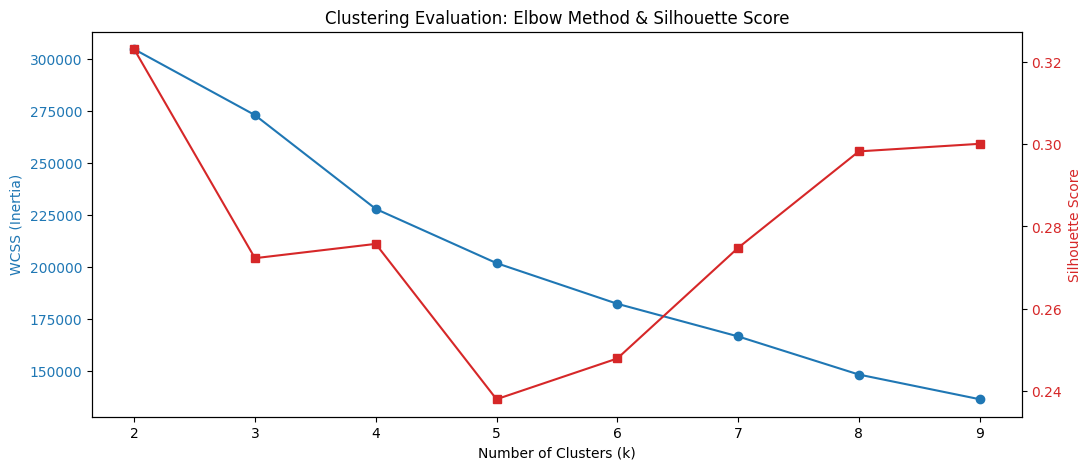

In [10]:
# Plotting Elbow and Silhouette side-by-side
fig, ax1 = plt.subplots(figsize=(12, 5))

# Elbow Plot (WCSS)
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('WCSS (Inertia)', color='tab:blue')
ax1.plot(k_range, wcss, marker='o', color='tab:blue', label='WCSS')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Silhouette Plot
ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color='tab:red')
ax2.plot(k_range, silhouette_avg, marker='s', color='tab:red', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Clustering Evaluation: Elbow Method & Silhouette Score')
plt.show()

#### 2. Create Chosen Cluster of K=3

In [11]:
chosen_k = 9

k_means_final = KMeans(n_clusters=chosen_k, random_state=RANDOM_SEED, n_init=K_MEANS_N_INIT)
cluster_labels = k_means_final.fit_predict(loitering_X_PCA)

#### 3. Visualize Chosen Cluster using UMAP Reduction

In [12]:
reducer = umap.UMAP(n_components=2, random_state=RANDOM_SEED)
loitering_X_UMAP = reducer.fit_transform(loitering_X_PCA)

/mnt/c/Users/frank/cs231-project-fishing/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


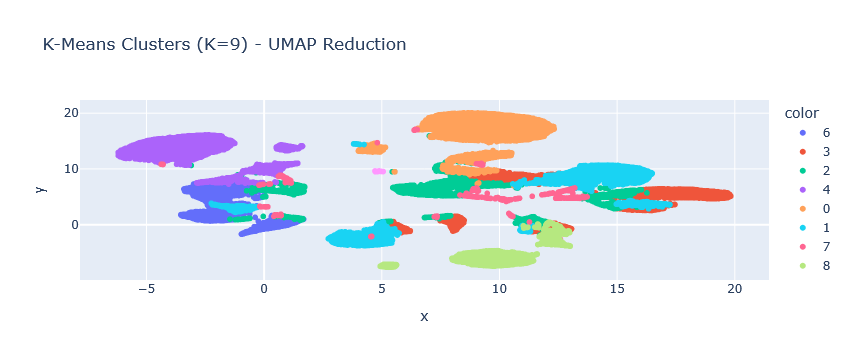

In [13]:
fig = px.scatter(x=loitering_X_UMAP[:, 0], y=loitering_X_UMAP[:, 1],
                 color=cluster_labels.astype(str),
                 title=f'K-Means Clusters (K={chosen_k}) - UMAP Reduction')
fig.show()